<a href="https://colab.research.google.com/github/joaoclaudio25/german_credit/blob/main/treino.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Classificação de risco de crédito com métodos clássicos de Machine Learning

**Dataset:** German Credit (Statlog), UCI Machine Learning Repository, licença CC BY 4.0 (Hofmann, 1994).
**Problema:** classificar cada solicitante como bom pagador (`0`) ou mau pagador (`1`).
**Projeto:** MVP da disciplina *Engenharia de Software para Sistemas Inteligentes*.

## Roteiro deste notebook

1. Preparação do ambiente
2. Carga dos dados
3. Análise exploratória
4. Seleção de atributos
5. Separação entre treino e teste (*holdout*)
6. Transformação dos dados (padronização e codificação)
7. Validação cruzada
8. Modelagem com configurações padrão
9. Otimização de hiperparâmetros
10. Avaliação no conjunto de teste
11. Comparação visual dos resultados
12. Escolha e exportação do modelo
13. Teste do modelo exportado
14. Principais achados e pontos de atenção
15. Conclusão

## Como executar

No Colab, use **Ambiente de execução → Executar tudo**. O notebook lê o CSV diretamente do GitHub, então é preciso ter conexão com a internet. A execução completa leva menos de dois minutos com a CPU padrão, sem necessidade de GPU.

## 1. Preparação do ambiente

Começamos importando as bibliotecas e fixando uma semente aleatória (`SEED = 42`). A semente faz com que a divisão dos dados, a validação cruzada e os modelos que usam aleatoriedade produzam sempre o mesmo resultado. Assim, quem executar o notebook verá os mesmos números.

Também registramos a versão do scikit-learn, porque o modelo exportado só pode ser carregado por uma versão compatível da biblioteca.

In [ ]:
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
SEED = 42
print("scikit-learn:", sklearn.__version__, "| pandas:", pd.__version__)

scikit-learn: 1.6.1 | pandas: 2.2.3


## 2. Carga dos dados

O dataset está em um repositório público no GitHub. Usamos a URL *raw*, que entrega o arquivo CSV puro, e o `pandas` lê o arquivo direto da internet. Assim o notebook não depende de upload manual e qualquer pessoa obtém exatamente a mesma base.

O arquivo tem 1000 linhas e 21 colunas: 20 atributos do solicitante e a coluna-alvo `credit_risk`.

In [ ]:
URL = "https://raw.githubusercontent.com/joaoclaudio25/german_credit/main/german_credit.csv"
df = pd.read_csv(URL)
print("Linhas e colunas:", df.shape)
df.head()

Linhas e colunas: (1000, 21)


,status_checking_account,duration_months,credit_history,purpose,credit_amount,savings_account,employment_since,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,existing_credits,job,people_liable,telephone,foreign_worker,credit_risk
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,0
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,1
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,0
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,0
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,1


## 3. Análise exploratória

Antes de modelar, verificamos a qualidade dos dados e o equilíbrio das classes.

- **Valores ausentes:** se houver valores nulos, eles precisariam de tratamento antes do treino. O dataset não os possui, então nenhuma imputação é necessária.
- **Balanceamento da classe-alvo:** a proporção entre bons e maus pagadores é o principal fato a considerar na escolha das métricas. Se uma classe for muito maior que a outra, a acurácia sozinha pode enganar.

In [ ]:
print("Valores nulos no total:", int(df.isnull().sum().sum()))

contagem = df["credit_risk"].value_counts().rename({0: "bons (0)", 1: "maus (1)"})
print(contagem)
print((contagem / len(df)).round(3))

Valores nulos no total: 0
credit_risk
bons (0)    700
maus (1)    300
Name: count, dtype: int64
credit_risk
bons (0)    0.7
maus (1)    0.3
Name: count, dtype: float64


## 4. Seleção de atributos

Usamos 8 dos 20 atributos originais, escolhidos na etapa anterior do projeto:

- **Categóricos:** `status_checking_account`, `credit_history`, `purpose`, `savings_account` e `employment_since`.
- **Numéricos:** `duration_months`, `credit_amount` e `age`.

Deixamos de fora dois atributos sensíveis, `personal_status_sex` (sexo e estado civil) e `foreign_worker` (nacionalidade). Usá-los para decidir crédito pode gerar discriminação, e a decisão de excluí-los foi tomada com base nesse risco ético, e não por desempenho.

In [ ]:
FEATURES_CAT = ["status_checking_account", "credit_history", "purpose",
                "savings_account", "employment_since"]
FEATURES_NUM = ["duration_months", "credit_amount", "age"]
FEATURES = FEATURES_CAT + FEATURES_NUM

X = df[FEATURES]
y = df["credit_risk"]
print("Atributos usados:", X.shape[1], "| alvo:", y.name)

Atributos usados: 8 | alvo: credit_risk


## 5. Separação entre treino e teste (*holdout*)

Separamos 20% dos dados como **conjunto de teste**. Esses dados ficam guardados até o fim do notebook e não são usados para escolher modelo nem hiperparâmetros. Eles servem para estimar o desempenho em casos novos.

O `stratify=y` mantém a mesma proporção de maus pagadores nos dois conjuntos. Como a classe de maus pagadores é minoritária, isso evita um conjunto de teste com proporção diferente da base real.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print(f"Treino: {len(X_train)} linhas | Teste: {len(X_test)} linhas")
print("Proporção de maus no treino:", round(y_train.mean(), 3),
      "| no teste:", round(y_test.mean(), 3))

Treino: 800 linhas | Teste: 200 linhas
Proporção de maus no treino: 0.3 | no teste: 0.3


## 6. Transformação dos dados

Os modelos precisam de números, e os atributos estão em escalas e formatos diferentes:

- **Categóricos** (`A11`, `A32` etc.) são convertidos em colunas 0/1 com `OneHotEncoder`. Cada categoria vira uma coluna própria, sem criar uma falsa ordem entre os códigos.
- **Numéricos** são **padronizados** com `StandardScaler`: subtraímos a média e dividimos pelo desvio-padrão, de modo que cada atributo fique com média 0 e desvio 1. Isso importa para o KNN e o SVM, que calculam distâncias. Uma variável como `credit_amount`, que vai de centenas a milhares, dominaria uma variável como `age` se não fosse padronizada.

A árvore de decisão não depende de escala, mas aplicamos a mesma transformação a todos os modelos para que a comparação seja justa.

Colocamos essas transformações dentro de um **pipeline**, junto com o modelo. Assim, a média e o desvio-padrão são calculados apenas com os dados de treino de cada etapa de validação cruzada. Se a padronização fosse feita antes da separação, parte da informação do teste vazaria para o treino.

In [ ]:
def criar_preprocessamento():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), FEATURES_CAT),
        ("num", StandardScaler(), FEATURES_NUM),
    ])

def criar_pipeline(modelo):
    return Pipeline([("prep", criar_preprocessamento()), ("clf", modelo)])

# Demonstração: o que o pré-processamento produz a partir do treino
preparado = criar_preprocessamento().fit(X_train)
print("Atributos antes:", X_train.shape[1], "| depois da transformação:",
      preparado.transform(X_train).shape[1])

Atributos antes: 8 | depois da transformação: 32


## 7. Validação cruzada

Com um único conjunto de treino, a escolha de um modelo ou de um hiperparâmetro poderia depender da sorte da divisão. Por isso usamos a **validação cruzada estratificada com 5 partições**: o treino é dividido em 5 blocos, e cada bloco serve, uma vez, como validação enquanto os outros 4 treinam o modelo. A média das 5 rodadas é a estimativa de desempenho.

A métrica principal é a **ROC AUC**. Ela mede a capacidade do modelo de ordenar os solicitantes do mais arriscado ao menos arriscado, independentemente do limiar de decisão. Como o problema é desbalanceado, a acurácia não é a melhor referência.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"roc_auc": "roc_auc", "accuracy": "accuracy", "precision": "precision",
           "recall": "recall", "f1": "f1"}

## 8. Modelagem com configurações padrão

Comparamos quatro algoritmos clássicos, além de uma regressão logística como referência:

- **KNN:** classifica cada solicitante pela maioria dos vizinhos mais próximos.
- **Árvore de classificação:** cria regras do tipo "se conta < 0 e prazo > 24 meses, então…". Usamos `class_weight="balanced"` para que a árvore dê mais peso aos maus pagadores.
- **Naive Bayes:** estima a probabilidade de cada classe assumindo independência entre atributos. É uma hipótese forte, mas simples e rápida.
- **SVM (kernel RBF):** procura a fronteira que separa as classes com a maior margem possível. Também usa `class_weight="balanced"` e `probability=True`, que ativa a estimativa de probabilidades usada no restante do projeto.
- **Regressão logística:** modelo linear simples, já usado nas etapas anteriores do projeto. Serve de referência.

Primeiro rodamos cada modelo com os parâmetros padrão, só para ter um ponto de partida.

In [ ]:
MODELOS = {
    "KNN": KNeighborsClassifier(),
    "Árvore de classificação": DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
    "Naive Bayes": GaussianNB(),
    "SVM": SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=SEED),
    "Regressão logística (referência)": LogisticRegression(max_iter=1000, class_weight="balanced"),
}

linhas = []
for nome, modelo in MODELOS.items():
    resultado = cross_validate(criar_pipeline(modelo), X_train, y_train,
                               cv=cv, scoring=SCORING, n_jobs=-1)
    linha = {"modelo": nome}
    linha.update({metrica: resultado[f"test_{metrica}"].mean() for metrica in SCORING})
    linha["desvio_roc_auc"] = resultado["test_roc_auc"].std()
    linhas.append(linha)

baseline = pd.DataFrame(linhas).round(3)
print("Validação cruzada no treino, com parâmetros padrão:")
baseline

Validação cruzada no treino, com parâmetros padrão:


,modelo,roc_auc,accuracy,precision,recall,f1,desvio_roc_auc
0,KNN,0.728,0.729,0.558,0.425,0.480,0.034
1,Árvore de classificação,0.621,0.679,0.466,0.475,0.470,0.032
2,Naive Bayes,0.709,0.635,0.453,0.621,0.507,0.048
3,SVM,0.789,0.725,0.530,0.700,0.602,0.041
4,Regressão logística (referência),0.764,0.700,0.497,0.700,0.581,0.053


## 9. Otimização de hiperparâmetros

Cada algoritmo tem parâmetros que controlam sua complexidade, e os valores padrão raramente são os melhores. Usamos `GridSearchCV`, que testa todas as combinações de uma grade de valores, avaliando cada uma pela validação cruzada no treino. A métrica de otimização é a ROC AUC.

O conjunto de teste continua fora deste processo. Os hiperparâmetros são escolhidos apenas com os dados de treino.

As grades são pequenas de propósito. Com 800 linhas, grades grandes levariam a ajustes excessivos aos dados de validação.

- **KNN:** número de vizinhos e peso pela distância.
- **Árvore:** profundidade máxima e número mínimo de amostras por folha, que controlam o tamanho da árvore.
- **Naive Bayes:** `var_smoothing`, que suaviza as variâncias estimadas.
- **SVM:** `C`, que controla a penalização de erros, e `gamma`, que define o alcance de cada exemplo na fronteira.
- **Regressão logística:** `C`, a força da regularização.

In [ ]:
GRADES = {
    "KNN": {"clf__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
            "clf__weights": ["uniform", "distance"]},
    "Árvore de classificação": {"clf__max_depth": [2, 3, 4, 5, 6, 8, None],
                                "clf__min_samples_leaf": [5, 10, 20, 40]},
    "Naive Bayes": {"clf__var_smoothing": [1e-9, 1e-7, 1e-5, 1e-3, 1e-1]},
    "SVM": {"clf__C": [0.1, 1, 10],
            "clf__gamma": ["scale", 0.01, 0.1]},
    "Regressão logística (referência)": {"clf__C": [0.01, 0.1, 1, 10]},
}

resultados = {}
for nome, modelo in MODELOS.items():
    busca = GridSearchCV(criar_pipeline(modelo), GRADES[nome], scoring="roc_auc",
                         cv=cv, n_jobs=-1, refit=True)
    busca.fit(X_train, y_train)
    resultados[nome] = busca
    print(f"{nome}: melhor ROC AUC na validação = {busca.best_score_:.3f} | {busca.best_params_}")

KNN: melhor ROC AUC na validação = 0.766 | {'clf__n_neighbors': 21, 'clf__weights': 'distance'}
Árvore de classificação: melhor ROC AUC na validação = 0.729 | {'clf__max_depth': 6, 'clf__min_samples_leaf': 40}
Naive Bayes: melhor ROC AUC na validação = 0.772 | {'clf__var_smoothing': 0.1}
SVM: melhor ROC AUC na validação = 0.792 | {'clf__C': 1, 'clf__gamma': 0.1}
Regressão logística (referência): melhor ROC AUC na validação = 0.770 | {'clf__C': 0.1}


## 10. Avaliação no conjunto de teste

Agora cada modelo, já com os melhores hiperparâmetros e treinado com todo o conjunto de treino, é avaliado nos 200 casos de teste que nunca foram usados antes.

Além da ROC AUC, olhamos métricas da classe de maus pagadores:

- **Recall:** dos maus pagadores reais, quantos o modelo identificou. Em crédito, deixar passar um mau pagador costuma ser o erro mais caro.
- **Precisão:** dos solicitantes marcados como maus, quantos realmente são.
- **F1:** média harmônica entre precisão e recall.

As previsões de classe usam o limiar de 0,5 sobre a probabilidade. Esse limiar é uma escolha de convenção, e voltaremos a ele nos pontos de atenção.

In [ ]:
linhas = []
for nome, busca in resultados.items():
    modelo_ajustado = busca.best_estimator_
    probabilidade = modelo_ajustado.predict_proba(X_test)[:, 1]
    previsao = (probabilidade >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, previsao).ravel()
    linhas.append({
        "modelo": nome,
        "roc_auc": roc_auc_score(y_test, probabilidade),
        "acuracia": accuracy_score(y_test, previsao),
        "precisao_mau": precision_score(y_test, previsao),
        "recall_mau": recall_score(y_test, previsao),
        "f1_mau": f1_score(y_test, previsao),
        "verdadeiros_maus": tp,
        "maus_nao_detectados": fn,
        "bons_barrados": fp,
        "bons_aprovados": tn,
    })

avaliacao = pd.DataFrame(linhas).sort_values("roc_auc", ascending=False).round(3)
avaliacao

,modelo,roc_auc,acuracia,precisao_mau,recall_mau,f1_mau,verdadeiros_maus,maus_nao_detectados,bons_barrados,bons_aprovados
4,Regressão logística (referência),0.817,0.735,0.540,0.783,0.639,47,13,40,100
2,Naive Bayes,0.801,0.785,0.649,0.617,0.632,37,23,20,120
3,SVM,0.798,0.750,0.614,0.450,0.519,27,33,17,123
0,KNN,0.779,0.760,0.676,0.383,0.489,23,37,11,129
1,Árvore de classificação,0.732,0.650,0.447,0.700,0.545,42,18,52,88


## 11. Comparação visual dos resultados

Os gráficos mostram duas coisas. As curvas ROC mostram o trade-off entre detectar maus pagadores e alarmes falsos, para todos os limiares possíveis. O gráfico de barras compara a estimativa obtida na validação cruzada com o resultado no teste.

Uma diferença grande entre as duas barras indicaria um modelo que se ajustou demais ao treino. Diferenças pequenas indicam que a estimativa da validação cruzada é confiável.

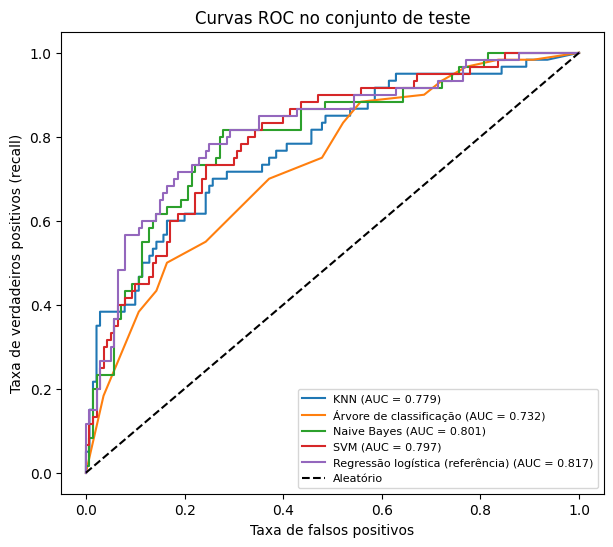

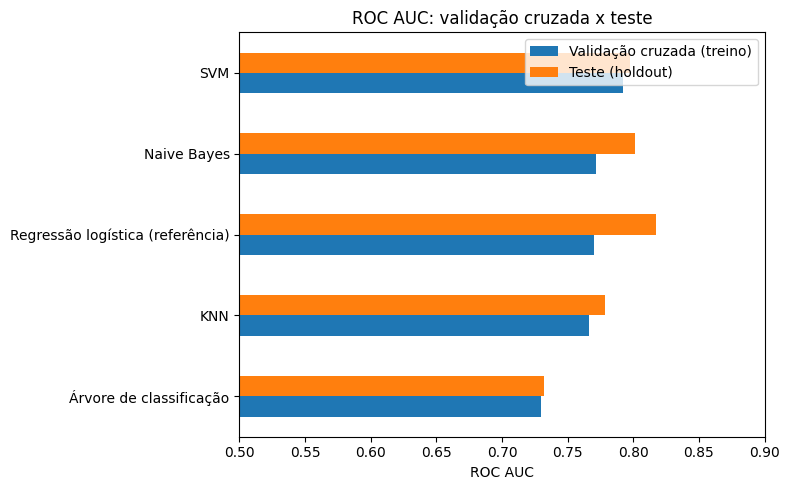

In [ ]:
fig, eixo = plt.subplots(figsize=(7, 6))
for nome, busca in resultados.items():
    probabilidade = busca.best_estimator_.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probabilidade)
    eixo.plot(fpr, tpr, label=f"{nome} (AUC = {roc_auc_score(y_test, probabilidade):.3f})")
eixo.plot([0, 1], [0, 1], "k--", label="Aleatório")
eixo.set_xlabel("Taxa de falsos positivos")
eixo.set_ylabel("Taxa de verdadeiros positivos (recall)")
eixo.set_title("Curvas ROC no conjunto de teste")
eixo.legend(loc="lower right", fontsize=8)
plt.show()

comparacao = pd.DataFrame({
    "Validação cruzada (treino)": {n: b.best_score_ for n, b in resultados.items()},
    "Teste (holdout)": {n: roc_auc_score(y_test, b.best_estimator_.predict_proba(X_test)[:, 1])
                        for n, b in resultados.items()},
}).sort_values("Validação cruzada (treino)")

comparacao.plot.barh(figsize=(8, 5), xlim=(0.5, 0.9), title="ROC AUC: validação cruzada x teste")
plt.xlabel("ROC AUC")
plt.tight_layout()
plt.show()

## 12. Escolha e exportação do modelo

A escolha do modelo final segue uma regra definida antes de olhar o conjunto de teste: vence o algoritmo com maior ROC AUC média na **validação cruzada do treino**. A regressão logística fica de fora dessa disputa, porque é apenas a referência.

Escolher pelo teste seria um erro metodológico. Os 200 casos de teste são poucos, e a diferença entre os melhores modelos é pequena. Escolher o que pareceu melhor no teste inflaria a estimativa de desempenho.

Depois de escolhido, o pipeline completo, com padronização, codificação e modelo, é salvo em um único arquivo. Isso garante que qualquer aplicação que carregue o arquivo aplique exatamente as mesmas transformações do treino.

In [ ]:
CANDIDATOS = ["KNN", "Árvore de classificação", "Naive Bayes", "SVM"]
vencedor = max(CANDIDATOS, key=lambda nome: resultados[nome].best_score_)
modelo_final = resultados[vencedor].best_estimator_

print("Modelo escolhido pela validação cruzada:", vencedor)
print("Hiperparâmetros:", resultados[vencedor].best_params_)

ARQUIVO = "modelo_risco_credito.joblib"
joblib.dump(modelo_final, ARQUIVO)
print("Modelo salvo em:", ARQUIVO)

try:
    from google.colab import files
    files.download(ARQUIVO)
except ImportError:
    print("Fora do Colab, o arquivo fica na pasta de execução.")

Modelo escolhido pela validação cruzada: SVM
Hiperparâmetros: {'clf__C': 1, 'clf__gamma': 0.1}
Modelo salvo em: modelo_risco_credito.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Teste do modelo exportado

Carregamos o arquivo salvo e comparamos as probabilidades com as do modelo original. Se os valores forem idênticos, a exportação preservou o modelo. Também conferimos os nomes das etapas do pipeline, porque a API do projeto acessa a etapa de pré-processamento pelo nome `prep`.

In [ ]:
modelo_carregado = joblib.load(ARQUIVO)
amostra = X_test.iloc[:5]

p_original = modelo_final.predict_proba(amostra)[:, 1]
p_carregado = modelo_carregado.predict_proba(amostra)[:, 1]

print("Probabilidades (original): ", np.round(p_original, 4))
print("Probabilidades (carregado):", np.round(p_carregado, 4))
print("Idênticas:", np.allclose(p_original, p_carregado))
print("Etapas do pipeline:", list(modelo_carregado.named_steps))
print("Versão do scikit-learn usada:", sklearn.__version__)

Probabilidades (original):  [0.2403 0.1599 0.6206 0.478  0.2712]
Probabilidades (carregado): [0.2403 0.1599 0.6206 0.478  0.2712]
Idênticas: True
Etapas do pipeline: ['prep', 'clf']
Versão do scikit-learn usada: 1.6.1


## 14. Principais achados e pontos de atenção

**Principais achados**

- **O sinal mais forte está na conta corrente.** Usar só essa variável, com a taxa de maus pagadores por categoria, já dá uma ROC AUC de 0,743 no teste. Os modelos aprendem a partir das 8 variáveis e melhoram essa referência, mas o ganho é modesto.
- **Os modelos lineares e probabilísticos se saíram bem.** Regressão logística, Naive Bayes e SVM ficaram próximos, com ROC AUC entre 0,797 e 0,817 no teste. A árvore de decisão foi a mais fraca, com ROC AUC de 0,73, o que sugere que regras simples e rígidas captam menos desse problema.
- **A otimização de hiperparâmetros ajudou na validação cruzada.** O SVM subiu de 0,789 para 0,792, o Naive Bayes de 0,709 para 0,772 e o KNN de 0,728 para 0,766. A melhora maior foi do Naive Bayes, que passou a usar um `var_smoothing` diferente do padrão.

**Pontos de atenção**

- **As diferenças entre os melhores modelos estão dentro da margem de erro.** No teste, há apenas 60 maus pagadores. O desvio-padrão da ROC AUC entre as partições da validação cruzada é de cerca de 0,04, então diferenças de 0,02 a 0,03 entre os três primeiros não são conclusivas. Por isso a escolha foi feita pela validação cruzada, que usa mais dados.
- **O limiar de 0,5 não é adequado para o SVM.** Com esse limiar, o SVM identifica apenas 45% dos maus pagadores no teste, contra 78% da regressão logística. A ordenação de risco do SVM é boa, mas o limiar precisa ser definido de acordo com o custo de cada tipo de erro. Essa é uma decisão de negócio, e não estatística.
- **O recall de maus pagadores varia muito entre os modelos.** KNN e SVM têm precisão maior, mas deixam passar mais maus pagadores. Árvore e regressão logística detectam mais maus pagadores, ao custo de barrar mais bons pagadores.
- **Os atributos sensíveis foram excluídos.** Essa escolha pode reduzir um pouco o desempenho, mas evita que o modelo aprenda discriminação por sexo ou nacionalidade. Isso deve ser registrado na documentação de uso do modelo.
- **A base é antiga e pequena.** Os dados são de 1994 e têm 1000 registros, em valores de marco alemão. Um modelo para uso real precisaria de dados atuais e de uma validação em produção.

Os números deste notebook são de uma execução de referência. Pequenas diferenças podem aparecer entre versões do scikit-learn, mas a ordem geral dos resultados deve se manter.

## 15. Conclusão

Este notebook percorreu o ciclo completo de um problema de classificação com métodos clássicos: carga, exploração, separação entre treino e teste, transformação com pipelines, validação cruzada, otimização de hiperparâmetros, avaliação no holdout, comparação e exportação.

Os quatro algoritmos exigidos alcançaram desempenho semelhante, e o SVM foi escolhido pela regra definida de antemão: maior ROC AUC na validação cruzada. O modelo exportado mantém todas as transformações, e foi testado para confirmar que o arquivo reproduz as mesmas probabilidades.

O resultado mais importante, porém, não é o algoritmo. É a combinação de um bom ranqueamento de risco, uma escolha de limiar alinhada ao negócio e a atenção às limitações dos dados. Esses são os próximos passos antes de qualquer uso real.